In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.pyplot as plt
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, PASTEL_CMAP, set_font_size, make_square_panel_row
GRID = False
# Font size + family (LaTeX Computer Modern Roman, via plot_config.mplstyle's
# default text.usetex=True) match plot_gauss_fixed_gauss.ipynb's companion
# figure exactly -- no local usetex/font.family override here any more.
FONT_SIZE = 18
LEGEND_FONT_SIZE = FONT_SIZE * 0.75  # change to resize legend text only
set_font_size(FONT_SIZE, LEGEND_FONT_SIZE)

# Warmer/more saturated time-axis colormap, local to this notebook only --
# PASTEL_CMAP (plot_config.py) stays the repo-wide default so other figures
# are untouched. Same blue -> cream -> red shape, richer at both ends and a
# warm gold-cream middle instead of the flatter gray-beige.
TIME_CMAP = LinearSegmentedColormap.from_list(
    'time_vivid',
    ['#3E6FA1', '#8FC1D9', '#FCEEC5', '#F4A87C', '#C0504D'],
)

# Gaussian Repulsion — Moving Obstacle

The Gaussian center circles the tip spring's fixed target (radius 10 cm) while the
tip spring (`lin_seg3`) tries to hold its reference at the origin, for three spring
stiffnesses: k = 2 N/m, k = 4 N/m, and k = 20 N/m.

**Goal:** overlay the end-effector path against the moving Gaussian goal, colored by
time, to compare how much the softer spring gets dragged along by the repulsion versus
the stiffer spring holding its ground.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
import os

In [3]:

def load_circle_window(path: str):
    """Return (t, ee_xy, gauss_xy) arrays trimmed to the circling phase, positions in cm."""
    d = np.load(path)
    t        = d['t']
    goal     = d['goal']      # (n, N_VC, 3)
    comp_pos = d['comp_pos']  # (n, N_VC, 3)

    # Circle starts when |gauss_goal_y| first exceeds 2 mm, ends when it last does
    gauss_goal_y = goal[:, 1, 1]
    mask = np.abs(gauss_goal_y) > 0.002
    idx_start = np.where(mask)[0][0]
    idx_end   = np.where(mask)[0][-1]

    sl = slice(idx_start, idx_end + 1)
    t_w        = t[sl] - t[idx_start]                # zero-based time
    ee_xy      = comp_pos[sl, 0, :2] * 100.0          # (n, 2)  lin_seg3 end-effector [m -> cm]
    gauss_xy   = goal[sl, 1, :2] * 100.0              # (n, 2)  gaussian goal [m -> cm]

    return t_w, ee_xy, gauss_xy


def make_segments(xy: np.ndarray):
    """Convert (n, 2) path into (n-1, 2, 2) line segments for LineCollection."""
    pts = xy.reshape(-1, 1, 2)
    return np.concatenate([pts[:-1], pts[1:]], axis=1)


# EE path: bold and opaque, the primary signal. Gaussian reference: TWO
# layers at the same radius -- (1) a translucent time-colored ring underneath
# so the actual moving-obstacle progression is visible (same time mapping as
# the EE path), and (2) a black dashed guide on top, itself only partially
# opaque, so the color underneath still shows through both the dash gaps AND
# the dashes themselves. Pure solid black on top made it unreadable as a
# "progression" -- this way both pieces of information (path shape + when).
EE_LW   = 5.5   # primary: end-effector path (solid, opaque)
GOAL_LW = 5.0   # secondary: gaussian goal, time-colored (translucent) -- thickened for readability
REF_LW  = 2.5   # Gaussian reference guide (black, dashed, translucent) -- unchanged, already right


def draw_panel(ax, t, ee_xy, gauss_xy, title: str, show_ylabel=True, cmap=TIME_CMAP):
    norm = mcolors.Normalize(vmin=0, vmax=t[-1])

    # Gaussian goal path -- translucent, colored by time (round caps/joins so
    # the many short per-segment pieces blend into one smooth ring).
    segs_g = make_segments(gauss_xy)
    lc_g = LineCollection(segs_g, cmap=cmap, norm=norm,
                          linewidth=GOAL_LW, alpha=0.35, zorder=1,
                          capstyle='round', joinstyle='round')
    lc_g.set_array(0.5 * (t[:-1] + t[1:]))
    ax.add_collection(lc_g)

    # Gaussian reference circle (radius 10 cm) -- black dashed guide, drawn
    # on top but only partially opaque so the time-colored ring underneath
    # still reads through it.
    theta = np.linspace(0, 2 * np.pi, 300)
    ax.plot(10.0 * np.cos(theta), 10.0 * np.sin(theta),
            '--', color='black', linewidth=REF_LW, alpha=0.7, zorder=2)

    # Origin
    ax.plot(0, 0, 'k+', markersize=8, markeredgewidth=1.5)

    # End-effector path -- solid, color encodes time (see the separate colorbar)
    segs_e = make_segments(ee_xy)
    lc_e = LineCollection(segs_e, cmap=cmap, norm=norm,
                          linewidth=EE_LW, zorder=3,
                          capstyle='round', joinstyle='round')
    lc_e.set_array(0.5 * (t[:-1] + t[1:]))
    ax.add_collection(lc_e)

    # No in-panel K label -- added by hand afterward (see the printed K values below).
    ax.set_xlabel('X (cm)')
    # Shared y-axis: only the left panel gets the label and the tick numbers,
    # so the right panel doesn't repeat them (paired-plot alignment).
    if show_ylabel:
        ax.set_ylabel('Y (cm)')
    else:
        ax.tick_params(labelleft=False)
    ax.set_aspect('equal')
    ax.grid(GRID)

    lim = 16.0
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)

    return lc_e  # return for shared colorbar


In [4]:
files = {
    'K = 2 (N/m)':  os.path.join('outputs', 'moving_gauss', 'k2_moving_gauss.npz'),
    'K = 4 (N/m)':  os.path.join('outputs', 'moving_gauss', 'k4_moving_gauss.npz'),
    'K = 20 (N/m)': os.path.join('outputs', 'moving_gauss', 'k20_moving_gauss.npz'),
}

# GaussianSpring.compute_force (VMC_utils/VirtualModels.py):
#   F = A * exp(-||delta||^2 / (2*sigma^2)) * delta
# sigma is fixed in GUI_MultiVMC_Config_moving.py (gauss_seg3 = GaussianSpring(
# strength=0.0, sigma=0.06)) and never logged per-timestep, so it's a constant
# here rather than read from the .npz.
GAUSS_SIGMA = 0.06  # [m] -- from GUI_MultiVMC_Config_moving.py, gauss_seg3

# Print the details behind each panel before plotting: full-run length, the
# detected circling-phase window, a sanity check that the end-effector
# actually orbits close to the 10 cm reference radius, and the Gaussian
# spring's parameters (A = strength, read from the recording since it's
# ramped up live in moving_gauss_test.py rather than fixed in the config;
# sigma is the fixed constant above).
for title, path in files.items():
    d = np.load(path)
    fs = float(d['control_freq'][0])
    t_w, ee_xy, gauss_xy = load_circle_window(path)
    r_ee = np.linalg.norm(ee_xy, axis=1)
    gauss_A = float(d['k_params'][:, 1].max())  # strength once enabled (0 beforehand)
    print(f'{title}   [{path}]')
    print(f'  Full run:        {len(d["t"])} samples   {d["t"][-1]:.1f} s   fs={fs:.0f} Hz')
    print(f'  Circling window: {len(t_w)} samples   {t_w[-1]:.2f} s')
    print(f'  EE radius range: [{r_ee.min():.2f}, {r_ee.max():.2f}] cm   (ref = 10.00 cm)')
    print(f'  Gaussian spring: A = {gauss_A:.1f} N   sigma = {GAUSS_SIGMA:.2f} m')
    print()

K = 2 (N/m)   [outputs/moving_gauss/k2_moving_gauss.npz]
  Full run:        10751 samples   37.0 s   fs=330 Hz
  Circling window: 6534 samples   19.80 s
  EE radius range: [4.87, 9.29] cm   (ref = 10.00 cm)
  Gaussian spring: A = 133.3 N   sigma = 0.06 m

K = 4 (N/m)   [outputs/moving_gauss/k4_moving_gauss.npz]
  Full run:        20592 samples   62.4 s   fs=330 Hz
  Circling window: 6534 samples   19.80 s
  EE radius range: [4.65, 5.74] cm   (ref = 10.00 cm)
  Gaussian spring: A = 140.0 N   sigma = 0.06 m

K = 20 (N/m)   [outputs/moving_gauss/k20_moving_gauss.npz]
  Full run:        17863 samples   58.4 s   fs=330 Hz
  Circling window: 6534 samples   19.80 s
  EE radius range: [3.78, 4.81] cm   (ref = 10.00 cm)
  Gaussian spring: A = 133.3 N   sigma = 0.06 m



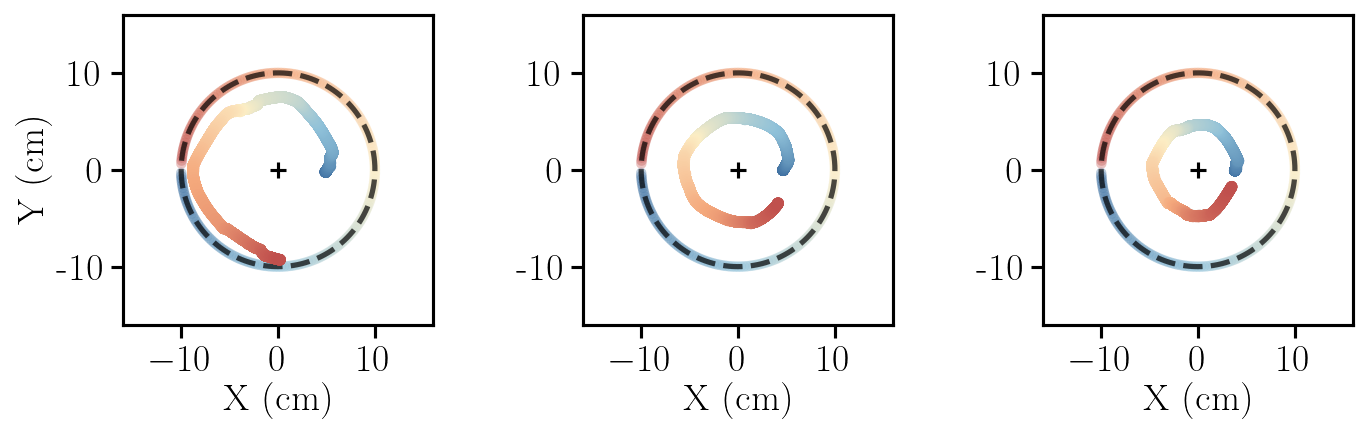

Saved → outputs/moving_gauss/xy_circle_comparison.pdf
Saved → outputs/moving_gauss/xy_circle_comparison.png

Panel K values (add by hand, left to right):
  K = 2 (N/m)
  K = 4 (N/m)
  K = 20 (N/m)


In [5]:

# ---- size / aspect for THIS graph only ----
# Font size/family now match plot_gauss_fixed_gauss.ipynb's companion figure
# exactly (FONT_SIZE=24, LaTeX Computer Modern Roman, set in the setup cell
# above) -- their figure widths don't need to match each other (that's a
# single 6in-wide posture plot, this is a 3-square-panel row; the old comment
# claiming a shared 9in width was wrong -- fixed_gauss has no 9in figure).
# Margins/gap below are re-tuned from the previous 18pt version, scaled up
# for the bigger font. Panels are laid out by make_square_panel_row
# (plot_config.py) -- see its docstring for why constrained_layout can't
# deliver a controllable gap for forced-square (aspect='equal') panels.
W_IN = 10.0   # in -- total figure width
GAP  = 1.0    # in -- TUNE THIS: physical gap between adjacent panels

LEFT_MARGIN   = 1.6   # in -- room for the left panel's y-label + tick numbers
RIGHT_MARGIN  = 0.2   # in -- breathing room after the right panel
BOTTOM_MARGIN = 1.05  # in -- room for x-label + tick numbers (all panels)
TOP_MARGIN    = 0.15  # in -- breathing room above the panels

N_PANELS = len(files)  # generalized for the extra middle-K panel
fig, axes = make_square_panel_row(N_PANELS, W_IN, GAP, LEFT_MARGIN, RIGHT_MARGIN, BOTTOM_MARGIN, TOP_MARGIN)

last_lc = None
t_max = 0.0

for i, (ax, (title, path)) in enumerate(zip(axes, files.items())):
    t, ee_xy, gauss_xy = load_circle_window(path)
    lc = draw_panel(ax, t, ee_xy, gauss_xy, title, show_ylabel=(i == 0), cmap=TIME_CMAP)
    ax.set_yticks([-10, 0, 10])
    ax.set_yticklabels(['-10', '0', '10'])
    ax.tick_params(axis='y', which='both', left=True, labelleft=True)
    last_lc = lc
    t_max = max(t_max, t[-1])

# No legend and no colorbar on this figure -- both are separate standalone
# files (next two cells) composed above this one by hand.
out = os.path.join('outputs', 'moving_gauss', 'xy_circle_comparison.pdf')
fig.savefig(out)
out_png = os.path.join('outputs', 'moving_gauss', 'xy_circle_comparison.png')
fig.savefig(out_png, dpi=300)
plt.show()
print(f"Saved → {out}")
print(f"Saved → {out_png}")

# No in-panel K label on the figure itself -- added by hand.
# Panel order is left -> right:
print("\nPanel K values (add by hand, left to right):")
for title in files:
    print(f"  {title}")

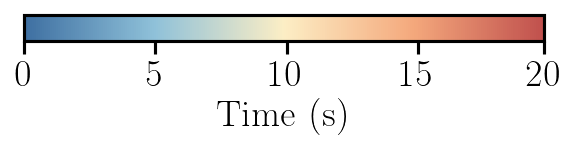

Saved → outputs/moving_gauss/xy_circle_colorbar.pdf


In [6]:
# Standalone time colorbar -- its own SVG/PDF, NOT part of the panel figure,
# composed above it by hand. Sized to match the OLD embedded vertical
# colorbar (fraction=0.025 against the H_IN=4.09in panel row -> measured
# 3.468in long x 0.173in thick) just rotated 90 deg, not stretched to the
# panel figure's full width.
BAR_LEN   = 3.468   # in -- old vertical colorbar's rendered length, rotated
BAR_THICK = 0.173   # in -- old vertical colorbar's rendered thickness
MARGIN_SIDE = 0.15  # in -- left/right breathing room
MARGIN_TEXT = 0.55  # in -- room below the bar for ticks + 'Time (s)' label

fig_w = BAR_LEN + 2 * MARGIN_SIDE
fig_h = BAR_THICK + MARGIN_TEXT

sm = plt.cm.ScalarMappable(cmap=TIME_CMAP, norm=mcolors.Normalize(vmin=0, vmax=t_max))
sm.set_array([])

fig_cb = plt.figure(figsize=(fig_w, fig_h))
ax_cb = fig_cb.add_axes([MARGIN_SIDE / fig_w, MARGIN_TEXT / fig_h,
                         BAR_LEN / fig_w, BAR_THICK / fig_h])
cbar = fig_cb.colorbar(sm, cax=ax_cb, orientation='horizontal', label='Time (s)')

# Explicit ticks -- the default locator was dropping the run's actual end
# (it stopped at 10 even though the data goes to ~19.8s). Show 0, every 5s,
# and the end -- labeled 20 (the trajectory's nominal circling duration:
# CTRL_HZ=10Hz x N_CIRCLE_STEPS=200 in moving_gauss_test.py = 20s; the 19.8s
# actually measured is just where the y-threshold window-detection happens
# to trim it) so the axis reads as a clean round end, not an odd 19.8.
ticks = list(np.arange(0, t_max, 5.0)) + [t_max]
cbar.set_ticks(ticks)
cbar.set_ticklabels([f'{tk:.0f}' if tk != t_max else '20' for tk in ticks])

out_cb = os.path.join('outputs', 'moving_gauss', 'xy_circle_colorbar.pdf')
fig_cb.savefig(out_cb)
plt.show()
print(f"Saved → {out_cb}")

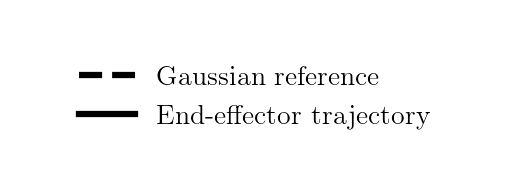

Saved → outputs/moving_gauss/xy_circle_legend.pdf


In [7]:
# Standalone legend -- its own SVG/PDF, NOT part of the panel figure,
# composed above it by hand (same as the colorbar). 2 entries, stacked one
# under the other (ncol=1): Gaussian reference (dashed) first, then
# End-effector trajectory (solid). Both drawn in solid black -- gray read as
# too faint for the dashed entry to actually show up.
#
# A bare plt.figure() with a legend but NO Axes doesn't reliably render in
# Jupyter's inline backend (it shows as the plain "<Figure ... with 0 Axes>"
# repr instead of an image) even though the saved PDF/SVG come out fine --
# so give it one invisible, full-figure Axes to draw on.
legend_handles = [
    Line2D([0], [0], color='black', lw=3.0, linestyle='--',
           label='Gaussian reference'),
    Line2D([0], [0], color='black', lw=3.0, linestyle='-',
           label='End-effector trajectory'),
]

fig_leg = plt.figure(figsize=(3.2, 1.1))
ax_leg = fig_leg.add_axes([0, 0, 1, 1])
ax_leg.axis('off')
ax_leg.legend(handles=legend_handles, loc='center', ncol=1, frameon=False)

out_leg = os.path.join('outputs', 'moving_gauss', 'xy_circle_legend.pdf')
fig_leg.savefig(out_leg)
plt.show()
print(f"Saved → {out_leg}")